## 1. Import Library

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix,
)
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset

In [2]:
df_train = pd.read_csv('data/movie_reviews.csv')
df_test = pd.read_csv('data/test_data.csv')

## 2. Exploratory Data Analysis

In [3]:
print("Train:", df_train.shape)
print("Test:", df_test.shape)
print("\nDistribusi label:")
print(df_train["label"].value_counts(dropna=False))

Train: (40000, 2)
Test: (10000, 2)

Distribusi label:
label
0    20049
1    19951
Name: count, dtype: int64


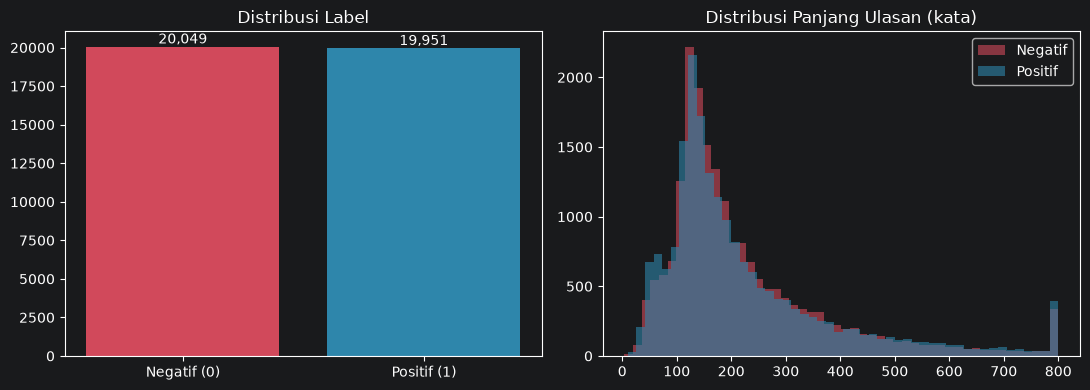

         count   mean    std   min    25%    50%    75%     max
label                                                          
0      20049.0  226.9  162.9   4.0  126.0  173.0  276.0  1487.0
1      19951.0  229.5  175.4  10.0  123.0  170.0  279.0  2459.0


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# distribusi label
counts = df_train["label"].value_counts().sort_index()
ax[0].bar(["Negatif (0)", "Positif (1)"], counts.values, color=["#d1495b", "#2e86ab"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[0].set_title("Distribusi Label")

# distribusi panjang ulasan (jumlah kata)
df_train["n_words"] = df_train["text"].str.split().str.len()
for lab, col, name in [(0, "#d1495b", "Negatif"), (1, "#2e86ab", "Positif")]:
    ax[1].hist(df_train.loc[df_train.label == lab, "n_words"].clip(upper=800),
               bins=50, alpha=0.6, color=col, label=name)
ax[1].set_title("Distribusi Panjang Ulasan (kata)")
ax[1].legend()

plt.tight_layout()
plt.savefig("fig/eda.png", dpi=200)
plt.show()

print(df_train.groupby("label")["n_words"].describe().round(1))

## 3. Preprocessing

In [7]:
import re
def clean_text(text):
    text = text.lower() #ubah semua menjadi lowercase
    text = re.sub(r"\d+", " ", text) #hapus angka
    text = re.sub(r"[^a-zA-Z0-9]", " ", text) #hapus non-alphabeth
    text = re.sub(r"\s+", " ", text) #rapikan spasi
    words = [w for w in text.split() if len(w) > 1 and len(w) < 20] #filter kata pendek
    return " ".join(words) #gabungkan lagi jdi string dengan pemisah " "

In [8]:
# 1) buang duplikat dulu (sebelum split, supaya tidak bocor ke validasi)
n_before = len(df_train)
df_train = df_train.drop_duplicates().reset_index(drop=True)
print("Duplikat dibuang:", n_before - len(df_train))

# 2) bersihkan teks, simpan hasilnya ke kolom yang sama
df_train["text"] = df_train["text"].fillna("").astype(str).apply(clean_text)
df_test["text"]  = df_test["text"].fillna("").astype(str).apply(clean_text)   # test WAJIB dibersihkan dengan cara yang sama

Duplikat dibuang: 258


cell di bawah ini ternyata ga ke apply ke data yg masuk ke modelling

In [6]:
# df_train["text"].apply(clean_text)
# df_train.drop_duplicates()

,text,label
0,If you havent seen this movie than you need to...,1
1,but Cinderella gets my vote not only for the w...,0
2,This movie is pretty cheesy but I do give it c...,1
3,I have not seen a Van Damme flick for a while ...,1
4,This is a sleeper It defines Nicholas Cage The...,1
...,...,...
39995,This movie is inspiring to anyone who is or ha...,1
39996,This film hits the heart with a reality like n...,1
39997,East Side Story is a documentary of musical co...,1
39998,And a selfadmitted one to boot At one point th...,0


In [9]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Id      10000 non-null  int64
 1   text    10000 non-null  str  
dtypes: int64(1), str(1)
memory usage: 156.4 KB


In [13]:
# Tangani pesan kosong tanpa membuang baris training.
#Baris yang berisi NaN diubah menajdi ""
X = df_train['text'].fillna("").astype(str)
y = df_train['label']

X_test = df_test['text'].fillna("").astype(str)

print("\nJumlah pesan kosong:", int(X.eq("").sum()))
print("Kelas:", sorted(y.unique()))


Jumlah pesan kosong: 0
Kelas: [np.int64(0), np.int64(1)]


In [14]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training:", len(X_train))
print("Validation:", len(X_valid))

Training: 31793
Validation: 7949


In [16]:
from sklearn.linear_model import SGDClassifier
baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,           # Mengubah teks jadi huruf kecil
            ngram_range=(1, 2),       # Bigram: dua token berurutan, misalnya bad message.
            min_df=2,                 # fitur harus muncul pada setidaknya dua dokumen training agar dipertahankan.
            max_features=500_000,     # Membatasi jumlah fitur yang dipertahankan hingga maksimum 100.000, untuk kontrol penggunaan memori dan waktu pelatihan
            sublinear_tf=True,        # Transformasi ini dapat mengurangi dominasi kata yang berulang sangat sering dalam satu dokumen.
        ),
    ),
    (
        "classifier",
        SGDClassifier(
            loss="modified_huber",
            alpha=2e-5,
            max_iter=50,
            random_state = 42,
        ),
    ),
])

baseline.fit(X_train, y_train)      #Latih model baseline

valid_pred = baseline.predict(X_valid)  #Untuk uji validasi model paai data X_valid

print("Accuracy:", round(accuracy_score(y_valid, valid_pred), 4))
print("Macro-F1:", round(f1_score(
    y_valid, valid_pred, average="macro"
), 4))

print("\nClassification report:")
print(classification_report(y_valid, valid_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(
    y_valid,
    valid_pred,
    labels=baseline.classes_,
))
print("Urutan kelas:", baseline.classes_)

Accuracy: 0.9095
Macro-F1: 0.9095

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      3973
           1       0.90      0.92      0.91      3976

    accuracy                           0.91      7949
   macro avg       0.91      0.91      0.91      7949
weighted avg       0.91      0.91      0.91      7949

Confusion matrix:
[[3583  390]
 [ 329 3647]]
Urutan kelas: [0 1]


In [17]:
# Latih ulang pada seluruh data berlabel.
baseline.fit(X, y)

# Prediksi data test yang tidak memiliki label.
test_pred = baseline.predict(X_test)

submission = pd.DataFrame({
    "Id": df_test["Id"],
    "label": test_pred,
})

# Pemeriksaan format dasar.
assert submission.columns.tolist() == ["Id", "label"]
assert len(submission) == len(df_test)
assert submission["Id"].equals(df_test["Id"])
assert submission["label"].notna().all()
assert set(submission["label"].unique()).issubset(set(y.unique()))

submission = pd.DataFrame({"Id": df_test["Id"], "label": test_pred})
submission.to_csv("submission_sgd_with_prep.csv", index=False)

print(submission["label"].value_counts(normalize=True).round(3))
submission.head()

label
1    0.501
0    0.499
Name: proportion, dtype: float64


,Id,label
0,0,0
1,1,1
2,2,0
3,3,1
4,4,1
